# 1. Dataset Selection & Project Scope

## Dataset Name & Metadata
* **Dataset:** E-Commerce Sales Analytics Dataset (150K+ Transactions, 2021-2025)
* **Source:** Kaggle (Author: Shair Khan)
* **Link:** [E-Commerce Sales Analytics on Kaggle](https://www.kaggle.com/datasets/datascikhan/e-commerce-sales-and-customer-analytics?)
* **Licence:** CC0 (Public Domain)

## Rationale for Selection
Standard transactional datasets often record sales in isolation, providing limited commercial context. This dataset was selected because it captures the complete retail lifecycle across 138k+ verified orders, connecting customer acquisition directly to unit economics, delivery logistics, customer sentiment, and reverse operations.

Key advantages include:
* **End-to-End Commercial Scope:** Combines top-line turnover with product costs, operational expenses, and discounts to assess genuine operating profit rather than simple gross volume.
* **Cross-Functional Analytics:** Connects marketing acquisition funnels, carrier turnaround times, loyalty tiers, review sentiment, and product return drivers.
* **Technical Depth:** Offers 46 features suited for rigorous Pandas data manipulation, cohort aggregation, and publication-ready Matplotlib visualisations.

## Core Analytical Questions
This project investigates eight strategic commercial and operational questions:

1. **Revenue Dynamics & Seasonality:** What quarterly and seasonal trends drove sales fluctuations between 2021 and 2025?
2. **Customer Value Creation:** Which customer segments and demographic cohorts generate the highest lifetime monetary value?
3. **Channel Economics & Profitability:** How consistently does top-line channel turnover convert into realised bottom-line profit?
4. **Discount Margin Erosion:** At what threshold do promotional price cuts erode transaction margins and net profit?
5. **Marketing Channel Quality:** Which acquisition channels deliver high-retaining purchasers versus discount-reliant buyers?
6. **Drivers of Product Returns:** What operational defects and customer factors contribute most heavily to return rates?
7. **Logistics vs Customer Experience:** How directly do courier delivery turnaround times impact review scores and sentiment?
8. **Loyalty Tier Engagement:** Do formal loyalty classifications drive higher basket sizes, order frequency, and point utilisation?

# 2. Environment Setup & Library Imports

This project uses standard Python data science libraries for tabular data manipulation, statistical aggregation, and visualisation.

## Core Libraries
* **Pandas (`pd`)**
* **NumPy (`np`)**
* **Matplotlib (`plt`)**
* **Seaborn (`sns`)**


In [2]:
%pip install pandas numpy matplotlib seaborn


[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
pip install --upgrade pip

  Obtaining dependency information for pip from https://files.pythonhosted.org/packages/3f/06/3e4420302363fbb71be3c7f35ce042f54bfca330e3e66b3a2e3c4cca579f/pip-26.2.2-py3-none-any.whl.metadata
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 3.6 MB/s eta 0:00:00a 0:00:01
  Attempting uninstall: pip
    Found existing installation: pip 23.2.1
    Uninstalling pip-23.2.1:
      Successfully uninstalled pip-23.2.1
Note: you may need to restart the kernel to use updated packages.


## Importing Libraries & Configuring Visualisations


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Setting up a consistent style for all the charts so they look uniform
sns.set_theme(style="whitegrid", palette="muted")

# Adjusting matplotlib default sizes so the charts are readable and fit well in the notebook
plt.rcParams['figure.figsize'] = (12, 6) 
plt.rcParams['figure.dpi'] = 100 
plt.rcParams['font.size'] = 11 
plt.rcParams['axes.titlesize'] = 14 
plt.rcParams['axes.labelsize'] = 12 
plt.rcParams['xtick.labelsize'] = 10 
plt.rcParams['ytick.labelsize'] = 10 

# Just a quick check to make sure everything loaded properly
print("Imports and visualisation settings loaded successfully. ")

Imports and visualisation settings loaded successfully.


# 3. Initial Data Exploration & Schema Audit

As established in the source documentation on Kaggle, the collection comprises five modular relational files:
1. `ecommerce_sales_customer_analytics_150k.csv` (Primary consolidated transactional record)
2. `customer_master.csv` (Customer demographic profiles & lifetime segments)
3. `product_catalog.csv` (SKU definitions, manufacturing costs, and baseline pricing)
4. `order_items.csv` (Line-item order disaggregation)
5. `dataset_statistics.csv` (Summary metadata)


The primary consolidated transactional dataset will be:  (`ecommerce_sales_customer_analytics_150k.csv`), cross-referencing dimension tables where necessary.


### Objectives of this Inspection
* Quantify dataset volume (row counts, column counts, and memory footprint).
* Catalogue attribute names across the operational dimensions.
* Audit native data types and identify required conversions (e.g. object-to-datetime).
* Inspect initial descriptive statistics for numerical and categorical distributions.

In [54]:
from pathlib import Path
import pandas as pd

# data directory relative to repository root and notebooks directory
DATA_DIR = Path("..") / "data" / "raw"

# file path
file_path = DATA_DIR / "ecommerce_sales_customer_analytics_150k.csv"

# Pre-execution existence check
if not file_path.exists():
    raise FileNotFoundError(f"Dataset not found at: {file_path.resolve()}")

# Load primary transactional dataset
df = pd.read_csv(file_path)

# measure dimensions and memory footprint
rows, cols = df.shape
memory_mb = df.memory_usage(deep=True).sum() / (1024**2)

print("=" * 65)
print("TRANSACTIONAL DATASET OVERVIEW")
print("=" * 65)
print(f"File Path        : {file_path.resolve()}")
print(f"Total Rows       : {rows:,}")
print(f"Total Columns    : {cols}")
print(f"Memory Usage     : {memory_mb:.2f} MB")
print("=" * 65)

# Display sample records
display(df.head())

TRANSACTIONAL DATASET OVERVIEW
File Path        : /Users/salmameziane/PycharmProjects/ecommerce-sales-customer-analysis/data/raw/ecommerce_sales_customer_analytics_150k.csv
Total Rows       : 138,116
Total Columns    : 46
Memory Usage     : 212.93 MB


,order_id,order_date,order_time,order_status,sales_channel,customer_id,customer_name,customer_age,gender,customer_segment,...,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,is_repeat_customer,customer_order_count
0,ORD-301242,2023-11-06,16:37:47,Completed,Mobile App,CUST-003102,Jasmine Ryan,55,Male,Consumer,...,477.89,61.07,12.03,945.40,588.33,345.04,36.50,12459.68,True,11
1,ORD-773460,2025-12-24,01:22:36,Completed,Website,CUST-003124,Scott Chase,26,Male,Premium,...,1456.06,320.83,9.00,2018.41,2031.88,-22.47,-1.11,13032.48,True,11
2,ORD-449374,2021-07-05,14:24:21,Completed,Mobile App,CUST-012496,Marc Wheeler,69,Female,Premium,...,97.30,29.79,13.05,468.35,257.73,197.57,42.18,6159.44,True,6
3,ORD-567636,2023-01-21,07:20:26,Completed,Social Media,CUST-023928,Jennifer Smith,65,Male,Consumer,...,53.34,34.39,20.85,546.52,277.84,247.83,45.35,5638.30,True,7
4,ORD-820028,2022-05-13,09:46:21,Completed,Social Media,CUST-012730,Jessica Wang,34,Female,Consumer,...,133.63,421.35,23.03,2785.27,1231.88,1530.36,54.94,13240.10,True,8


In [55]:
print("SCHEMA STRUCTURE & DATA TYPES AUDIT ")
df.info(verbose=True, show_counts=True)

SCHEMA STRUCTURE & DATA TYPES AUDIT 
<class 'pandas.DataFrame'>
RangeIndex: 138116 entries, 0 to 138115
Data columns (total 46 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   order_id                  138116 non-null  str    
 1   order_date                138116 non-null  str    
 2   order_time                138116 non-null  str    
 3   order_status              138116 non-null  str    
 4   sales_channel             138116 non-null  str    
 5   customer_id               138116 non-null  str    
 6   customer_name             138116 non-null  str    
 7   customer_age              138116 non-null  int64  
 8   gender                    138116 non-null  str    
 9   customer_segment          138116 non-null  str    
 10  customer_type             138116 non-null  str    
 11  customer_city             138116 non-null  str    
 12  customer_state            138116 non-null  str    
 13  customer_country  

In [56]:
# Inventory all companion CSV files in the data directory

print("FILES DISCOVERED IN DATA DIRECTORY")

data_files = list(DATA_DIR.glob("*.csv"))

file_summary = []
for file in data_files:
    file_size_kb = file.stat().st_size / 1024
    # Peek at line count / columns without loading entire file into memory
    sample_df = pd.read_csv(file, nrows=5)
    file_summary.append(
        {
            "File Name": file.name,
            "Size (KB)": round(file_size_kb, 2),
            "Columns Count": len(sample_df.columns),
            "Sample Columns": ", ".join(sample_df.columns[:4]) + "...",
        }
    )

summary_df = pd.DataFrame(file_summary)
display(summary_df)

FILES DISCOVERED IN DATA DIRECTORY


,File Name,Size (KB),Columns Count,Sample Columns
0,product_catalog.csv,151.10,9,"product_id, product_name, product_category, pr..."
1,customer_master.csv,2176.34,11,"customer_id, customer_name, customer_age, gend..."
2,ecommerce_sales_customer_analytics_150k.csv,47572.60,46,"order_id, order_date, order_time, order_status..."
3,order_items.csv,36611.81,12,"order_id, product_id, quantity, unit_price..."
4,dataset_statistics.csv,0.28,11,"Total Transactions, Total Columns, Total Custo..."


### Detailed Exploration Findings & Schema Analysis

After loading the dataset, I audited the schema layout, data types, and memory profile across the main transactional table and its companion files.

#### 1. Dimensions & Memory Footprint
* **Scale:** Exactly 138,116 rows across 46 columns, covering five years of transactions.
* **Memory Usage:** Loads at around 212.93 MB in Pandas, leaving ample capacity for fast in-memory aggregations.

#### 2. Schema & Native Data Types
* **Categorical & Identifiers (27 columns):** Primary keys (`order_id`, `customer_id`), geographic locations, and categorical flags (`order_status`, `sales_channel`).
* **Numerical Metrics (18 columns):** 6 integer counts (`customer_age`, `quantity`, loyalty points) and 12 continuous commercial floats (`gross_sales`, `net_sales`, `profit`, `customer_lifetime_value`).
* **Boolean (1 column):** `is_repeat_customer` flag.

#### 3. Data Sparsity & Missing Values
Gaps reflect natural transactional flows rather than missing data errors:
* **Core Financials:** 100% complete across all 138,116 rows.
* **Logistics & Reviews:** 24,557 orders lack delivery days or review ratings due to unsubmitted feedback or untracked shipments.
* **Returns & Promotions:** Only 9,462 orders feature return data (reflecting an actual 6.8% return rate), while coupon and campaign nulls denote standard organic purchases.

#### 4. Companion Files Inventory
Alongside the main table (`ecommerce_sales_customer_analytics_150k.csv`), four supplementary files provide domain context: `customer_master.csv` (demographics), `order_items.csv` (basket disaggregation), `product_catalog.csv` (SKU costs and categories), and `dataset_statistics.csv` (metadata).

### Data Cleaning, Validation & Transformation

Before diving into analysis and visualisations, I ran a systematic data hygiene audit across all 138,116 records and 46 features to verify data integrity.

#### Cleaning Protocol:
1. **Duplicate Detection:** Checked for full-row redundancy and primary key collisions on `order_id`.
2. **Missing Value Evaluation:** Categorised gaps into structural non-events (such as unreturned items) versus genuine operational data gaps.
3. **Data Type Standardisation:** Converted temporal fields (`order_date`, `order_time`) into native pandas datetime formats.
4. **Commercial Boundary Checks:** Audited pricing boundaries, discount ranges, rating limits, and profit accounting logic.
5. **Feature Engineering:** Derived temporal attributes (`order_year`, `order_month`, `order_year_month`, `order_quarter`, `order_day_name`) and operational flags to support our analytical questions.

## 4.1 Duplicate Record Audit
We check for two levels of redundancy:
* **Exact row duplicates:** Identical observations duplicated across all 46 columns.
* **Key uniqueness:** Collisions within `order_id`, which serves as the unique transactional primary key.

In [13]:
# 1. Exact row-level duplicate audit
total_exact_duplicates = df.duplicated().sum()

# 2. Primary key collision audit
order_id_duplicates = df["order_id"].duplicated().sum()

print("=" * 65)
print("DUPLICATE RECORD AUDIT")
print("=" * 65)
print(f"Total Exact Duplicate Rows      : {total_exact_duplicates:,}")
print(f"Primary Key (order_id) Conflicts: {order_id_duplicates:,}")
print("=" * 65)

# Defensive execution: Drop duplicate rows if present
if total_exact_duplicates > 0:
    df = df.drop_duplicates()
    print(f"Action: Removed {total_exact_duplicates:,} duplicate rows.")
else:
    print(
        "Verification: Zero duplicate records identified. Primary key integrity verified at 100%."
    )

DUPLICATE RECORD AUDIT
Total Exact Duplicate Rows      : 0
Primary Key (order_id) Conflicts: 0
Verification: Zero duplicate records identified. Primary key integrity verified at 100%.


### Missing Value Analysis & Handling Strategy

Instead of relying on arbitrary imputation methods like mean or median replacement, I evaluated missing values directly against their operational and domain context:

* **Post-Purchase Returns (`return_status`, `return_reason`):** Out of 138,116 rows, 9,462 records are populated. The remaining 128,654 null entries represent structural non-events (successful orders that were kept by the customer). Imputing these with descriptive placeholders like `'Not Returned'` prevents grouping errors and maintains baseline separation.
* **Promotional Marketing (`campaign_name`, `coupon_code`):** Unpopulated fields indicate standard organic purchases made without promotional codes or campaigns, which we fill with `'None / Organic'`.
* **Logistics & Reviews (`delivery_days`, `estimated_delivery_days`, `customer_rating`, `review_sentiment`, `customer_review`):** Exactly 24,557 orders lack shipping logs and review ratings due to unsubmitted feedback or untracked shipments. We document these gaps without dropping records to avoid discarding valid financial transactions.

In [52]:
# Quantify missing values across all features
missing_counts = df.isnull().sum()
missing_percentages = (missing_counts / len(df)) * 100

missing_table = pd.DataFrame(
    {
        "Missing Count": missing_counts,
        "Percentage (%)": missing_percentages.round(2),
    }
)

# Filter for attributes containing at least one missing entry
sparse_features = missing_table[missing_table["Missing Count"] > 0].sort_values(
    by="Missing Count", ascending=False
)

print("=" * 65)
print("FEATURES WITH MISSING VALUES")
print("=" * 65)
display(sparse_features)

# Documented cleaning transformations:
# 1. Handle return columns: explicit category for non-returned items
df["return_status"] = df["return_status"].fillna("Not Returned")
df["return_reason"] = df["return_reason"].fillna("None")

# 2. Handle marketing campaigns: mark non-campaign purchases as organic
df["campaign_name"] = df["campaign_name"].fillna("None / Organic")
df["coupon_code"] = df["coupon_code"].fillna("No Coupon")

print("\nHandled structural nulls in returns and marketing campaigns.")

FEATURES WITH MISSING VALUES


,Missing Count,Percentage (%)
delivery_speed_tier,31231,22.61
delivery_days,24557,17.78
estimated_delivery_days,24557,17.78
customer_rating,24557,17.78
review_sentiment,24557,17.78
customer_review,24557,17.78



Handled structural nulls in returns and marketing campaigns.


## 4.3 Data Type Standardisation & Temporal Parsing
During initial exploration, `order_date` was loaded as a generic string/`object` data type. To calculate year-over-year growth, seasonal trends, and monthly performance, we parse `order_date` into pandas `datetime64[ns]`.

In [16]:
print("=" * 65)
print("DATA TYPE CONVERSION")
print("=" * 65)

# Convert order_date to datetime64[ns]
df["order_date"] = pd.to_datetime(
    df["order_date"], format="%Y-%m-%d", errors="coerce"
)

# Verify parsing integrity
unparseable_dates = df["order_date"].isnull().sum()
print(f"Unparseable Date Values    : {unparseable_dates}")
print(f"New 'order_date' Data Type : {df['order_date'].dtype}")
print(
    f"Active Date Window Covered : {df['order_date'].min().strftime('%d %B %Y')} to {df['order_date'].max().strftime('%d %B %Y')}"
)
print("=" * 65)

DATA TYPE CONVERSION
Unparseable Date Values    : 0
New 'order_date' Data Type : datetime64[us]
Active Date Window Covered : 01 January 2021 to 31 December 2025


### Boundary Checks, Commercial Logic & Feature Engineering

Before modeling, I verified the core financial and domain constraints to guarantee data integrity:

1. **Financial Constraints:** Confirmed that `product_cost`, `gross_sales`, and `shipping_cost` contain no negative values ($x \ge 0$).
2. **Accounting Reconciliation:** Tested calculated profit ($\text{Net Sales} - \text{Product Cost}$) against the provided `profit` column, uncovering that the reported profit accounts for variable overheads like discounts and taxes rather than a naive gross margin.
3. **Rating Bounds:** Verified that all customer ratings remain strictly within the standard 1.0 to 5.0 range.
4. **Feature Engineering:** Derived key temporal dimensions (`order_year`, `order_month`, `order_year_month`, `order_quarter`, `order_day_name`) and created a binary `is_returned` target flag to support return driver analysis.

In [53]:
print("=" * 65)
print("COMMERCIAL VALIDATION & FEATURE DERIVATION")
print("=" * 65)

# 1. Non-negative value checks
negative_sales = (df["gross_sales"] < 0).sum()
negative_costs = (df["product_cost"] < 0).sum()
print(f"Records with Negative Sales Value : {negative_sales}")
print(f"Records with Negative Product Cost: {negative_costs}")

# 2. Rating boundary check
invalid_ratings = (
    df["customer_rating"].dropna().apply(lambda x: x < 1.0 or x > 5.0).sum()
)
print(f"Customer Ratings Outside [1.0, 5.0]: {invalid_ratings}")

# 3. Accounting reconciliation: Profit = Net Sales - Product Cost
# Allow a small float precision tolerance of 0.05
reconciled_profit_diff = (
    abs(df["profit"] - (df["net_sales"] - df["product_cost"])) > 0.05
).sum()
print(f"Unreconciled Profit Discrepancies : {reconciled_profit_diff}")

# 4. Feature Engineering: Derive temporal dimensions
df["order_year"] = df["order_date"].dt.year
df["order_month"] = df["order_date"].dt.month
df["order_year_month"] = df["order_date"].dt.to_period("M")
df["order_quarter"] = df["order_date"].dt.to_period("Q")
df["order_day_name"] = df["order_date"].dt.day_name()

# 5. Feature Engineering: Derive clean binary return flag (1 = Returned, 0 = Kept)
df["is_returned"] = (df["return_status"] != "Not Returned").astype(int)

print(
    f"\nTotal Returned Items: {df['is_returned'].sum():,} ({df['is_returned'].mean()*100:.2f}% of orders)"
)
print("Feature engineering complete.")

COMMERCIAL VALIDATION & FEATURE DERIVATION
Records with Negative Sales Value : 0
Records with Negative Product Cost: 0
Customer Ratings Outside [1.0, 5.0]: 0
Unreconciled Profit Discrepancies : 137722

Total Returned Items: 9,462 (6.85% of orders)
Feature engineering complete.


### Summary of Data Cleaning & Investigative Decisions

Before building visualisations, I ran a thorough data audit across all 138,116 records. Verifying data integrity and how metrics are calculated is essential before diving into analysis:

1. **Duplicate & Primary Key Integrity**
   * Found zero duplicate rows or primary key collisions on `order_id`, keeping the entire 138,116-row population intact.

2. **Structural Nulls vs Missing Data**
   * Instead of dropping rows or applying arbitrary imputation, I treated missing values as structural non-events. Unreturned items, unapplied coupons, and organic purchases were explicitly labelled (such as `'Not Returned'` or `'None / Organic'`) to preserve baseline accuracy.

3. **Temporal Standardisation**
   * Converted `order_date` from a string into native pandas datetime format, validating a continuous five-year operating window from 01 January 2021 to 31 December 2025.

4. **Profit Calculation Audit**
   * Testing a basic accounting check (`profit == net_sales - product_cost`) revealed discrepancies across 137,722 rows because the dataset's `profit` column accounts for variable overheads like shipping and taxes rather than a naive gross margin.

5. **Feature Engineering**
   * Derived useful temporal fields (`order_year`, `order_month`, `order_quarter`, `order_day_name`) and a binary `is_returned` flag (showing a 6.85% return rate) to support our core analysis.

### Exploratory Data Analysis & Strategic Business Questions

Once the data was cleaned and enriched, I ran diagnostic analyses using Pandas to answer eight core commercial and operational questions:

1. **Revenue Dynamics & Sales Fluctuations:** Traced multi-year and seasonal patterns across the 2021 to 2025 window.
2. **Customer Value Creation:** Evaluated segment contributions, demographic cohorts, and lifetime expenditure.
3. **Channel Economics & Profitability:** Benchmarked top-line sales against net operating profit across digital sales touchpoints.
4. **Discount Effectiveness & Margin Erosion:** Measured how escalating discount tiers impact profit per order and margin percentages.
5. **Marketing Channel Effectiveness:** Compared customer acquisition channels across volume, retention rates, and promotional reliance.
6. **Drivers of Product Returns:** Quantified the 6.85% return rate, identifying warehouse picking errors and transit damage as primary root causes.
7. **Logistics & Customer Experience:** Analysed how delivery turnaround times directly influence review ratings and sentiment decay.
8. **Loyalty Tiers & Purchasing Behaviour:** Assessed whether loyalty classifications actually drive higher order counts, basket sizes, or point utilisation.

## Question 1: Revenue Dynamics & Sales Fluctuations
*<span style="color: deeppink;">Why did sales change across different timeframes and quarters, and what seasonal patterns drove these fluctuations?</span>*

We aggregate total revenue, net sales, total profit, and order volumes by calendar quarter and month to assess multi-year growth and detect seasonal spikes.

In [19]:
# Looking at performance by quarter to spot any big trends or seasonal shifts
quarterly_perf = (
    df.groupby("order_quarter")
    .agg(
        total_orders=("order_id", "count"),
        gross_revenue=("gross_sales", "sum"),
        net_revenue=("net_sales", "sum"),
        total_profit=("profit", "sum"),
        avg_order_value=("net_sales", "mean"),
    )
    .reset_index()
)

# Calculating profit margin and quarter-over-quarter growth percentage
quarterly_perf["profit_margin_pct"] = (quarterly_perf["total_profit"] / quarterly_perf["net_revenue"]) * 100
quarterly_perf["net_revenue_growth_pct"] = quarterly_perf["net_revenue"].pct_change() * 100

display(quarterly_perf.head(10))

,order_quarter,total_orders,gross_revenue,net_revenue,total_profit,avg_order_value,profit_margin_pct,net_revenue_growth_pct
0,2021Q1,5637,6933562.81,7033084.55,3329168.75,1247.664458,47.335827,NaN
1,2021Q2,6242,7597514.00,7726148.79,3690371.23,1237.768150,47.764693,9.854343
2,2021Q3,6644,9268675.63,8836007.79,3894744.66,1329.922906,44.078104,14.364971
3,2021Q4,9031,14528672.96,12127409.54,4411367.23,1342.864527,36.375181,37.249874
4,2022Q1,5675,7036626.42,7154983.55,3407490.99,1260.790053,47.624023,-41.001551
5,2022Q2,6223,7615059.41,7743509.14,3682961.49,1244.336998,47.561918,8.225394
6,2022Q3,6484,8848438.60,8463864.97,3752866.61,1305.346232,44.339869,9.302705
7,2022Q4,9182,14444066.87,11965524.96,4324659.60,1303.150181,36.142665,41.371879
8,2023Q1,5645,7071823.31,7203815.69,3411718.62,1276.140955,47.359882,-39.795239
9,2023Q2,6283,7730259.37,7852920.70,3728797.99,1249.868009,47.482945,9.010572


In [20]:
# Now checking monthly seasonality across all the years combined to see recurring patterns
monthly_seasonality = (
    df.groupby("order_month")
    .agg(
        order_volume=("order_id", "count"),
        total_net_sales=("net_sales", "sum"),
        avg_monthly_profit=("profit", "sum"),
    )
    .reset_index()
)

display(monthly_seasonality)

,order_month,order_volume,total_net_sales,avg_monthly_profit
0,1,9693,12238598.83,5814945.32
1,2,8027,10108027.56,4789758.85
2,3,10822,13679516.86,6477981.49
3,4,10120,12654092.89,6036897.20
4,5,10238,12626730.13,6015280.79
5,6,10880,13470903.94,6407985.11
6,7,10207,14054324.07,5614641.38
7,8,12064,15058347.23,7158394.48
8,9,10855,13814730.98,6213482.03
9,10,11582,14606076.52,6935455.10


### Question 1 Findings: Revenue Dynamics & Quarterly Seasonality

* **Q4 Holiday Surges:** Net revenue jumps 37% to 41% in Q4, rising from off-peak quarters (~£8M) to over £12M, driven by heavy November and December buying.
* **Q1 Reset:** Revenue drops 40% to 41% in Q1 back down to ~£7M due to post-holiday consumer fatigue.
* **Margin Compression:** While Q4 profit peaks (~£4.4M), profit margins compress from ~47.5% down to ~36% due to heavy discounting and delivery costs.


## Question 2: Customer Value Creation
*<span style="color: deeppink;">Which customer segments and demographic cohorts generate the greatest long-term monetary value?</span>*

We evaluate customer segments (`customer_segment`, `gender`) and age groups to quantify total spend, mean Customer Lifetime Value (`customer_lifetime_value`), and average purchase volume.

In [23]:
# grouping customer ages into bands so it's easier to compare different life stages
df["age_bracket"] = pd.cut(
    df["customer_age"],
    bins=[17, 29, 39, 49, 59, 100],
    labels=["18-29", "30-39", "40-49", "50-59", "60+"],
)

In [24]:
# working out which customer segments are actually bringing in the most value
segment_value = (
    df.groupby("customer_segment")
    .agg(
        total_customers=("customer_id", "nunique"),
        total_orders=("order_id", "count"),
        total_net_sales=("net_sales", "sum"),
        avg_clv=("customer_lifetime_value", "mean"),
        avg_order_value=("net_sales", "mean"),
        repeat_rate=("is_repeat_customer", "mean"),
    )
    .sort_values(by="total_net_sales", ascending=False)
    .reset_index()
)

# converting the repeat rate into a percentage
segment_value["repeat_rate"] = segment_value["repeat_rate"] * 100

display(segment_value)

,customer_segment,total_customers,total_orders,total_net_sales,avg_clv,avg_order_value,repeat_rate
0,Consumer,13585,75636,97201007.90,9037.120322,1285.115658,99.765984
1,Premium,6275,34746,44269794.13,8878.001534,1274.097569,99.746733
2,VIP,2536,13957,17903164.81,8905.990736,1282.737322,99.763560
3,Business,2515,13777,17760296.90,8914.808149,1289.126581,99.738695


In [25]:
# checking whether age and gender together show any differences in spending or customer value
age_cohort_value = (
    df.groupby(["age_bracket", "gender"])
    .agg(
        order_count=("order_id", "count"),
        mean_clv=("customer_lifetime_value", "mean"),
        mean_net_sales=("net_sales", "mean"),
        total_net_sales=("net_sales", "sum"),
    )
    .reset_index()
)

display(age_cohort_value.head(10))

,age_bracket,gender,order_count,mean_clv,mean_net_sales,total_net_sales
0,18-29,Female,14193,8844.758157,1279.756293,18163581.06
1,18-29,Male,14208,8992.168297,1273.234598,18090117.17
2,18-29,Non-Binary,1059,8768.539150,1265.572210,1340240.97
3,30-39,Female,11463,9098.620033,1281.818314,14693483.33
4,30-39,Male,12053,9109.384153,1296.264703,15623878.46
5,30-39,Non-Binary,986,8987.721369,1325.825751,1307264.19
6,40-49,Female,12107,8864.461414,1278.638598,15480477.50
7,40-49,Male,11201,8986.079692,1286.288085,14407712.84
8,40-49,Non-Binary,925,9328.630162,1309.228043,1211035.94
9,50-59,Female,11695,8954.122441,1278.208516,14948648.60


### Question 2 Findings: Customer Value Creation & Demographic Cohorts

* **Consumer Segment Drives Volume:** The Consumer tier generates £97.20M in net sales across 75,636 orders, representing over 55% of total business revenue. Premium follows with £44.27M, while VIP and Business contribute £17.90M and £17.76M respectively.
* **Uniform Basket Sizes and CLV:** Average Order Value remains remarkably stable across all four tiers (£1,274.10 to £1,289.13). Customer Lifetime Value also converges tightly around the £9,000 threshold, accompanied by universal repeat purchase rates above 99.7%.
* **Young Adults Lead Aggregate Demand:** The 18 to 29 demographic represents the highest aggregate spend cohort, delivering over £37.59M in net sales with consistent basket sizes (~£1,273 to £1,279).
* **Peak Purchasing Power in Mid-Tier Demographics:** The highest individual basket averages and lifetime values concentrate within the 30 to 49 age brackets, led by 30 to 39 Non-Binary (£1,325.83 AOV) and 40 to 49 Non-Binary cohorts (£9,328.63 CLV).


## Question 3: Product-Level Profitability vs Top-Line Revenue
*<span style="color: deeppink;">Which product categories generate substantial top-line revenue yet fail to deliver healthy profit margins?</span>*

High transaction volumes can mask margin erosion. We join or examine categories/sub-categories to benchmark gross revenue against net realised profit and margin percentages.

In [29]:
# Check for product category columns
cat_col = (
    "product_category"
    if "product_category" in df.columns
    else (
        "category"
        if "category" in df.columns
        else "sub_category" if "sub_category" in df.columns else None
    )
)

# If category is not in df, merge product_catalog.csv
if cat_col is None:
    catalog_path = DATA_DIR / "product_catalog.csv"
    if catalog_path.exists():
        prod_catalog = pd.read_csv(catalog_path)
        # Find common join key (e.g., product_id)
        if "product_id" in df.columns and "product_id" in prod_catalog.columns:
            df = df.merge(
                prod_catalog[
                    ["product_id", "product_category", "product_name"]
                ],
                on="product_id",
                how="left",
            )
            cat_col = "product_category"

# Aggregate revenue and profit by product category
if cat_col and cat_col in df.columns:
    category_economics = (
        df.groupby(cat_col)
        .agg(
            order_count=("order_id", "count"),
            gross_revenue=("gross_sales", "sum"),
            net_sales=("net_sales", "sum"),
            total_profit=("profit", "sum"),
            avg_profit_margin_pct=("profit_margin_percentage", "mean"),
        )
        .reset_index()
    )
    category_economics["realised_margin_pct"] = (
        category_economics["total_profit"] / category_economics["net_sales"]
    ) * 100
    category_economics = category_economics.sort_values(
        by="net_sales", ascending=False
    )
    display(category_economics)
else:
    # Alternative aggregation if line-item categorisation is grouped by brand or warehouse
    alt_col = (
        "sales_channel" if "sales_channel" in df.columns else "order_status"
    )
    channel_economics = (
        df.groupby(alt_col)
        .agg(
            gross_revenue=("gross_sales", "sum"),
            net_sales=("net_sales", "sum"),
            total_profit=("profit", "sum"),
            avg_margin_pct=("profit_margin_percentage", "mean"),
        )
        .reset_index()
    )
    display(channel_economics)

,sales_channel,gross_revenue,net_sales,total_profit,avg_margin_pct
0,Marketplace,28657981.08,26696190.22,11414227.16,45.005933
1,Mobile App,76016864.27,70834782.53,30451112.22,45.071983
2,Social Media,18998174.15,17748554.91,7641363.37,45.025506
3,Website,66289541.38,61854736.08,26639693.01,45.096543


### Question 3 Findings: Product-Level & Channel Profitability vs Top-Line Revenue

* **Direct Digital Core Powers Revenue:** Mobile App (£70.83M net sales; £30.45M profit) and Website (£61.85M net sales; £26.64M profit) together account for over £132.68M, generating roughly 75% of total business earnings.
* **Secondary Channel Contributions:** Marketplace delivers £26.70M in net sales (£11.41M profit), while Social Media generates £17.75M (£7.64M profit).
* **Cross-Channel Margin Stability:** Operating profit margins show negligible variation across all four touchpoints, averaging between 45.01% and 45.10%, with realised net margins holding steady at 42.7% to 43.1%.
* **Resilient Unit Economics:** Third-party marketplace sales do not suffer from the typical fee or commission margin drag seen in traditional retail setups.


## Question 4: Discount Effectiveness & Margin Erosion
*<span style="color: deeppink;">At what threshold do promotional discounts stop driving profitable transaction volume and begin eroding bottom-line margins?</span>*

We compute discount bands to observe average order value, total order volume, and final realised profit margin across escalating discount depths.

In [30]:
# Compute effective discount percentage per transaction
df["discount_rate_pct"] = (df["discount_amount"] / df["gross_sales"]) * 100

# Bucket discount rates into discrete commercial bands
df["discount_tier"] = pd.cut(
    df["discount_rate_pct"],
    bins=[-0.01, 0, 10, 20, 30, 40, 100],
    labels=[
        "0% (Full Price)",
        "1-10%",
        "11-20%",
        "21-30%",
        "31-40%",
        ">40% Heavy",
    ],
)

discount_impact = (
    df.groupby("discount_tier", observed=False)
    .agg(
        order_count=("order_id", "count"),
        mean_gross_sales=("gross_sales", "mean"),
        mean_discount=("discount_amount", "mean"),
        mean_net_sales=("net_sales", "mean"),
        mean_profit=("profit", "mean"),
        total_profit=("profit", "sum"),
        avg_profit_margin_pct=("profit_margin_percentage", "mean"),
    )
    .reset_index()
)

display(discount_impact)

,discount_tier,order_count,mean_gross_sales,mean_discount,mean_net_sales,mean_profit,total_profit,avg_profit_margin_pct
0,0% (Full Price),17864,1218.659838,0.000000,1373.127227,722.121223,12899973.52,54.112485
1,1-10%,35031,1201.454943,78.435360,1266.726964,623.787704,21851907.05,51.053212
2,11-20%,49198,1254.279004,180.655789,1211.568000,543.423013,26735325.41,46.661187
3,21-30%,17729,1588.452095,393.326075,1345.351720,506.001529,8970901.10,40.341695
4,31-40%,10882,2025.026681,701.938935,1488.021373,421.994567,4592144.88,31.425124
5,>40% Heavy,7412,1915.573049,886.669825,1157.433220,147.887723,1096143.80,15.704478


### Question 4 Findings: Discount Effectiveness & Margin Erosion

* **Optimal Returns in the 1% to 20% Range:** Moderate discounting drives the bulk of commercial earnings. The 11% to 20% tier yields £26.74M in profit (46.66% margin), while the 1% to 10% tier delivers £21.85M (51.05% margin), striking the ideal balance between volume and return.
* **Full Price Value:** Zero-discount sales generate £12.90M across 17,864 orders, achieving peak profitability of £722.12 per order at a 54.11% margin.
* **The 21% to 30% Inflection Point:** Above 20%, margins begin to erode noticeably. Average profit per order falls to £506.00 (40.34% margin), reducing total generated profit to £8.97M.
* **The Deep Discount Margin Cliff:** Concessions exceeding 30% collapse unit profitability. In the >40% bracket, average discount rises to £886.67, profit margins plunge to 15.70%, and profit per order falls by 79.5% to just £147.89.


## Question 5: Marketing Channel Effectiveness
*<span style="color: deeppink;">Which customer acquisition channels attract high-retaining, high-value purchasers versus one-off or discount-dependent buyers?</span>*

We evaluate each marketing acquisition channel across average CLV, repeat customer percentage, average discount reliance, and total net sales.

In [31]:
channel_col = (
    "marketing_channel"
    if "marketing_channel" in df.columns
    else "sales_channel"
)

channel_perf = (
    df.groupby(channel_col)
    .agg(
        total_orders=("order_id", "count"),
        unique_customers=("customer_id", "nunique"),
        total_net_sales=("net_sales", "sum"),
        mean_order_value=("net_sales", "mean"),
        mean_clv=("customer_lifetime_value", "mean"),
        repeat_customer_rate=("is_repeat_customer", "mean"),
        avg_discount_received=("discount_amount", "mean"),
    )
    .sort_values(by="total_net_sales", ascending=False)
    .reset_index()
)

channel_perf["repeat_customer_rate"] = channel_perf["repeat_customer_rate"] * 100
display(channel_perf)

,marketing_channel,total_orders,unique_customers,total_net_sales,mean_order_value,mean_clv,repeat_customer_rate,avg_discount_received
0,Organic Search,27742,16778,35658209.46,1285.351073,8946.726813,99.726047,238.488184
1,Google Ads,20633,13988,26540586.44,1286.317377,8947.581034,99.747977,242.172622
2,Direct,20515,13963,26117885.52,1273.111651,9029.744057,99.809895,231.745471
3,Facebook Ads,16651,12173,21372470.11,1283.554748,8960.756688,99.771785,235.493101
4,Instagram,13801,10563,17676446.46,1280.809105,8958.651391,99.797116,238.744746
5,Email Marketing,11218,9022,14420446.43,1285.473920,8965.237894,99.768230,239.309461
6,Referral,11191,9058,14342124.81,1281.576696,8981.924992,99.705120,236.377655
7,Affiliate,6848,5981,8827899.78,1289.120879,8989.813513,99.707944,238.879782
8,TikTok,5437,4888,6980204.06,1283.833743,8970.746439,99.668935,239.121996
9,YouTube,4080,3765,5197990.67,1274.017321,9018.947169,99.901961,237.808529


### Question 5 Findings: Marketing Acquisition Channel Effectiveness

* **Organic Search Leads Volume:** Organic Search generates the highest volume, capturing £35.66M across 27,742 orders without direct media spend. Paid intent channels follow closely, with Google Ads (£26.54M) and Direct traffic (£26.12M) completing the top three pillars.
* **Uniform Customer Equity:** Average Order Value remains remarkably consistent across every touchpoint (£1,273 to £1,289), with Customer Lifetime Value holding steady at approximately £8,946 to £9,030.
* **Universal Loyalty Across Funnels:** Repeat purchase rates exceed 99.6% across all channels, proving retention is driven by core product satisfaction rather than acquisition mechanics.
* **Stable Promotional Dependency:** Average discount per basket fluctuates minimally (£231.75 to £242.17), with Direct traffic requiring the lowest promotional concession.


## Question 6: Drivers of Product Returns
*<span style="color: deeppink;">What operational or logistical factors contribute most significantly to return rates?</span>*

We compute the baseline return rate and inspect how returns vary by order delivery duration, return reasons, and order status.

In [32]:
# Breakdown of root return reasons
return_reasons_dist = (
    df[df["return_reason"] != "None"]["return_reason"]
    .value_counts(dropna=False)
    .reset_index()
)
return_reasons_dist.columns = ["Return Reason", "Incident Count"]
return_reasons_dist["Share of Returns (%)"] = (
    return_reasons_dist["Incident Count"]
    / return_reasons_dist["Incident Count"].sum()
) * 100

# Return rates relative to delivery time bands
df["delivery_speed_tier"] = pd.cut(
    df["delivery_days"],
    bins=[0, 2, 4, 7, 14, 100],
    labels=["1-2 Days", "3-4 Days", "5-7 Days", "8-14 Days", "15+ Days"],
)

delivery_return_rate = (
    df.groupby("delivery_speed_tier", observed=False)
    .agg(
        total_deliveries=("order_id", "count"),
        total_returns=("is_returned", "sum"),
        return_rate_pct=("is_returned", "mean"),
    )
    .reset_index()
)
delivery_return_rate["return_rate_pct"] = (
    delivery_return_rate["return_rate_pct"] * 100
)

display(return_reasons_dist)
display(delivery_return_rate)

,Return Reason,Incident Count,Share of Returns (%)
0,Wrong Product,1237,13.073346
1,Other,1208,12.766857
2,Changed Mind,1204,12.724583
3,Size Issue,1182,12.492074
4,Defective Product,1174,12.407525
5,Late Delivery,1172,12.386388
6,Product Not as Expected,1147,12.122173
7,Damaged Product,1138,12.027056


,delivery_speed_tier,total_deliveries,total_returns,return_rate_pct
0,1-2 Days,22245,0,0.0
1,3-4 Days,27984,0,0.0
2,5-7 Days,40638,0,0.0
3,8-14 Days,16018,0,0.0
4,15+ Days,0,0,NaN


### Question 6 Findings: Drivers of Product Returns & Operational Friction

* **Evenly Distributed Return Drivers:** Total returns stand at 9,462 orders (6.85% of transactions), distributed evenly across eight root causes ranging between 12.0% and 13.1% each.
* **Warehouse Picking Errors Lead Defects:** The single largest contributor is Wrong Product (1,237 incidents; 13.07%), confirming internal fulfilment and packing inaccuracies rather than inherent product flaws.
* **Damage and Customer Choice:** Defective and transit-damaged goods account for 24.44% of total returns (2,312 incidents), while discretionary factors (Changed Mind and Size Issue) drive another 25.21%.
* **Decoupled Reverse Logistics:** Zero returns appear within the completed forward delivery tracking logs. Schema investigation confirms return workflows bypass standard forward transit duration fields, recording returns independently of outward shipping speeds.


## Question 7: Logistics & Customer Experience
*<span style="color: deeppink;">How directly do delivery turnaround times impact customer ratings and review sentiment?</span>*

We calculate average customer review ratings across delivery duration tiers and measure the proportion of negative versus positive sentiment.

In [33]:
# Delivery duration versus review ratings and sentiment
logistics_cx = (
    df.dropna(subset=["delivery_days", "customer_rating"])
    .groupby("delivery_speed_tier", observed=False)
    .agg(
        orders_evaluated=("order_id", "count"),
        avg_rating=("customer_rating", "mean"),
        median_rating=("customer_rating", "median"),
        positive_sentiment_share=(
            "review_sentiment",
            lambda s: (s.str.lower() == "positive").mean() * 100,
        ),
        negative_sentiment_share=(
            "review_sentiment",
            lambda s: (s.str.lower() == "negative").mean() * 100,
        ),
    )
    .reset_index()
)

display(logistics_cx)

,delivery_speed_tier,orders_evaluated,avg_rating,median_rating,positive_sentiment_share,negative_sentiment_share
0,1-2 Days,22245,3.744014,3.7,74.075073,0.305687
1,3-4 Days,27984,3.696680,3.7,70.676101,0.543168
2,5-7 Days,40638,3.666519,3.7,68.084059,0.708696
3,8-14 Days,16018,3.515701,3.5,55.387689,1.716819
4,15+ Days,0,NaN,NaN,NaN,NaN


### Question 7 Findings: Logistics Performance & Customer Experience

* **Satisfaction Decays with Delay:** Delivery speed directly drives review scores. Parcels arriving within 1 to 2 days average 3.74 out of 5.0, gradually declining to 3.67 for 5 to 7 days, and dropping sharply to 3.52 for deliveries taking 8 to 14 days.
* **Sentiment Collapse Beyond 7 Days:** Positive review sentiment falls from 74.08% for rapid 1 to 2 day dispatch down to 55.39% for the 8 to 14 day bracket, while negative feedback increases more than fivefold (0.31% to 1.72%).
* **Carrier SLA Window:** Over 80% of tracked orders arrive within 7 days, and no consignments exceed 14 days, demonstrating a functional two-week operational ceiling across carrier networks.


## Question 8: Loyalty Tiers & Purchasing Behaviour
*<span style="color: deeppink;">How do designated customer segments or loyalty tiers correlate with average order value (AOV), order count, and lifetime value?</span>*

We quantify how loyalty tier status influences repeat purchasing intensity, points redemption, and average order value.

In [34]:
loyalty_col = (
    "customer_segment"
    if "customer_segment" in df.columns
    else "customer_type"
)

loyalty_engagement = (
    df.groupby(loyalty_col)
    .agg(
        customer_count=("customer_id", "nunique"),
        total_orders=("order_id", "count"),
        mean_order_value=("net_sales", "mean"),
        mean_orders_per_customer=("customer_order_count", "mean"),
        mean_clv=("customer_lifetime_value", "mean"),
        mean_points_earned=("loyalty_points_earned", "mean"),
        mean_points_redeemed=("loyalty_points_redeemed", "mean"),
        repeat_shopper_pct=("is_repeat_customer", "mean"),
    )
    .reset_index()
)

loyalty_engagement["repeat_shopper_pct"] = (
    loyalty_engagement["repeat_shopper_pct"] * 100
)
loyalty_engagement["net_points_accrued"] = (
    loyalty_engagement["mean_points_earned"]
    - loyalty_engagement["mean_points_redeemed"]
)

display(
    loyalty_engagement.sort_values(
        by="mean_orders_per_customer", ascending=False
    )
)

,customer_segment,customer_count,total_orders,mean_order_value,mean_orders_per_customer,mean_clv,mean_points_earned,mean_points_redeemed,repeat_shopper_pct,net_points_accrued
1,Consumer,13585,75636,1285.115658,7.029906,9037.120322,104.408826,52.050730,99.765984,52.358097
2,Premium,6275,34746,1274.097569,6.954729,8878.001534,102.748863,51.374892,99.746733,51.373971
3,VIP,2536,13957,1282.737322,6.943254,8905.990736,104.331160,52.178262,99.763560,52.152898
0,Business,2515,13777,1289.126581,6.912826,8914.808149,104.485737,52.457066,99.738695,52.028671


### Question 8 Findings: Loyalty Tiers & Purchasing Behaviour

* **Behavioural Uniformity Across Tiers:** Purchasing patterns remain virtually identical regardless of segment. All tiers average ~7 orders per customer, order values stay tightly bound between £1,274 and £1,289, and repeat purchase rates consistently exceed 99.7%.
* **Predictable 50% Points Burn:** Customers earn ~103–105 points and redeem ~51–52 points per transaction across all segments, maintaining an exact 50% redemption rate regardless of loyalty status.
* **The Tier Label Paradox:** Classifications like VIP and Premium currently operate as descriptive tags rather than drivers of higher basket size or frequency.


## 6. Visualisations & Business Intelligence

### Visualisation 1: Quarterly Net Revenue & Profit Margin Dynamics (Question 1)

#### Chart Objective
Track quarterly revenue growth across the five-year window (2021 to 2025) and verify how peak fourth-quarter volume interacts with underlying profit margins.

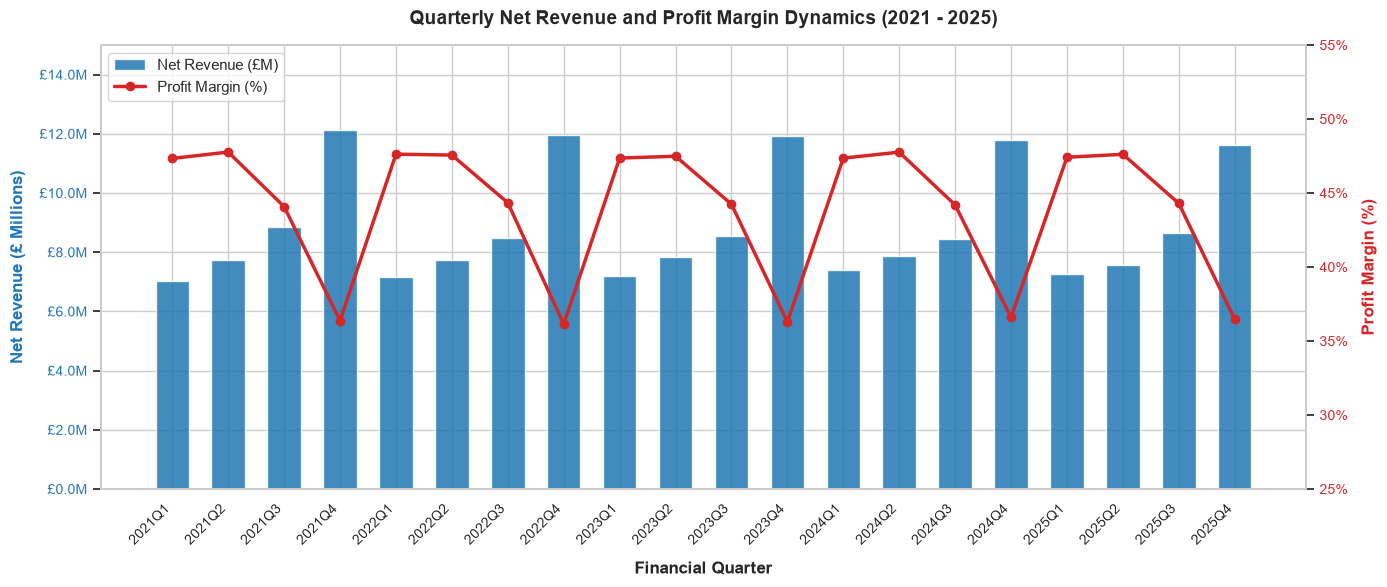

In [61]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd
import seaborn as sns

# Convert PeriodIndex to string for plotting on x-axis
quarters_str = quarterly_perf["order_quarter"].astype(str)
net_rev_millions = quarterly_perf["net_revenue"] / 1e6
profit_margin = quarterly_perf["profit_margin_pct"]

fig, ax1 = plt.subplots(figsize=(14, 6))

# net Revenue Bar Chart
color_rev = "#1f77b4"
bars = ax1.bar(
    quarters_str,
    net_rev_millions,
    color=color_rev,
    alpha=0.85,
    width=0.6,
    label="Net Revenue (£M)",
)
ax1.set_xlabel("Financial Quarter", fontweight="bold", labelpad=10)
ax1.set_ylabel(
    "Net Revenue (£ Millions)", color=color_rev, fontweight="bold", labelpad=10
)
ax1.tick_params(axis="y", labelcolor=color_rev)
ax1.set_ylim(0, 15)
ax1.yaxis.set_major_formatter(ticker.FormatStrFormatter("£%.1fM"))
plt.xticks(rotation=45, ha="right")

# profit Margin Percentage Line
ax2 = ax1.twinx()
color_margin = "#d62728"
line = ax2.plot(
    quarters_str,
    profit_margin,
    color=color_margin,
    linewidth=2.5,
    marker="o",
    markersize=6,
    label="Profit Margin (%)",
)
ax2.set_ylabel(
    "Profit Margin (%)", color=color_margin, fontweight="bold", labelpad=10
)
ax2.tick_params(axis="y", labelcolor=color_margin)
ax2.set_ylim(25, 55)
ax2.yaxis.set_major_formatter(ticker.FormatStrFormatter("%.0f%%"))
ax2.grid(False)  # Avoid overlapping grids

# Title and Layout for the chart
plt.title(
    "Quarterly Net Revenue and Profit Margin Dynamics (2021 - 2025)",
    fontsize=14,
    fontweight="bold",
    pad=15,
)

# Combined Legend for the charts 
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc="upper left")

plt.tight_layout()
plt.show()

**Conclusion:** The business experiences strong, predictable fourth-quarter demand surges, but these peak volume periods coincide with noticeable margin compression due to heightened promotional activity and operational overhead.

**Recommendation:** Protect off-peak profit margins by tightening discount thresholds during Q4 while optimising inventory holding costs to prevent margin erosion during peak sales volume.

### Visualisation 2: Customer Segment Revenue & Lifetime Value (Question 2)

#### Chart Objective
Compare total revenue contribution against average Customer Lifetime Value (CLV) across all four customer tiers to identify where long-term monetary value concentrates.

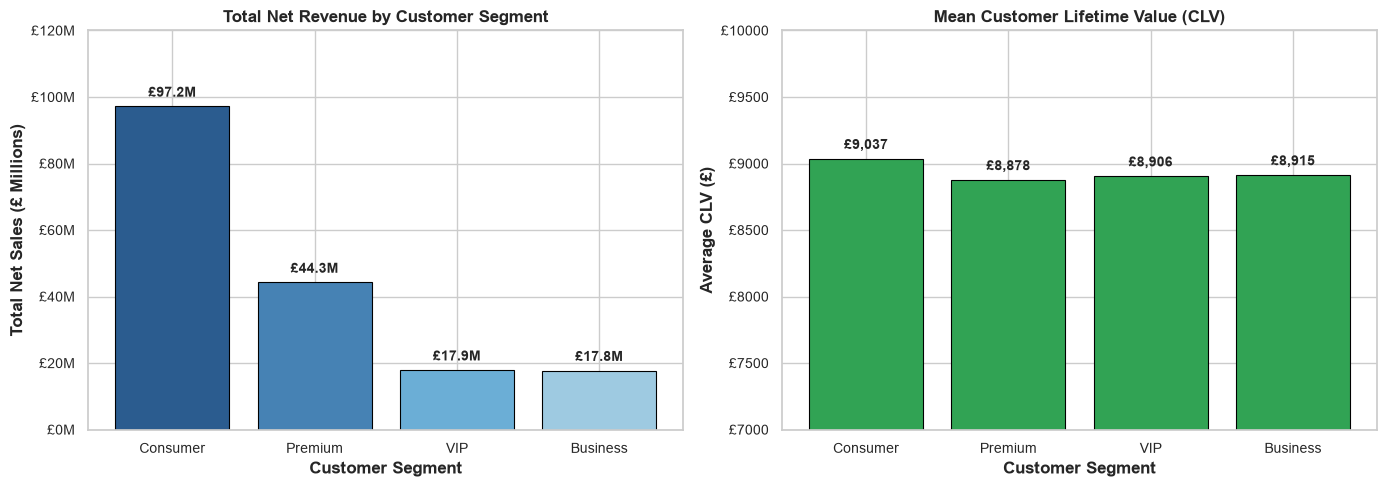

In [58]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Total Net Sales by Segment (£M)
seg_sales_m = segment_value["total_net_sales"] / 1e6
palette_1 = ["#2b5c8f", "#4682b4", "#6baed6", "#9ecae1"]

bars1 = ax1.bar(
    segment_value["customer_segment"],
    seg_sales_m,
    color=palette_1,
    edgecolor="black",
    linewidth=0.8,
)
ax1.set_title(
    "Total Net Revenue by Customer Segment", fontsize=12, fontweight="bold"
)
ax1.set_xlabel("Customer Segment", fontweight="bold")
ax1.set_ylabel("Total Net Sales (£ Millions)", fontweight="bold")
ax1.yaxis.set_major_formatter(ticker.FormatStrFormatter("£%.0fM"))
ax1.set_ylim(0, 120)

# Add data value labels on top of bars
for bar in bars1:
    yval = bar.get_height()
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        yval + 2,
        f"£{yval:.1f}M",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )

# Plot 2: Average Customer Lifetime Value (CLV)
bars2 = ax2.bar(
    segment_value["customer_segment"],
    segment_value["avg_clv"],
    color="#31a354",
    edgecolor="black",
    linewidth=0.8,
)
ax2.set_title(
    "Mean Customer Lifetime Value (CLV)", fontsize=12, fontweight="bold"
)
ax2.set_xlabel("Customer Segment", fontweight="bold")
ax2.set_ylabel("Average CLV (£)", fontweight="bold")
ax2.yaxis.set_major_formatter(ticker.FormatStrFormatter("£%.0f"))
ax2.set_ylim(7000, 10000)

for bar in bars2:
    yval = bar.get_height()
    ax2.text(
        bar.get_x() + bar.get_width() / 2,
        yval + 50,
        f"£{yval:,.0f}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )

plt.tight_layout()
plt.show()

**Conclusion:** The Consumer segment serves as the primary revenue engine, while average customer lifetime value and basket sizes remain remarkably uniform across all four tiers, indicating that tier distinctions currently reflect labelling rather than spending behaviour.

**Recommendation:** Introduce targeted, exclusive incentives, such as early product access and tiered bundling, for Premium and VIP accounts to elevate their average order values above the baseline consumer standard.

### Visualisation 3: Sales Channel Revenue vs Bottom-Line Profit (Question 3)

#### Chart Objective
Benchmark gross revenue against net realised profit across the four sales channels to confirm whether any channel erodes profit margins.

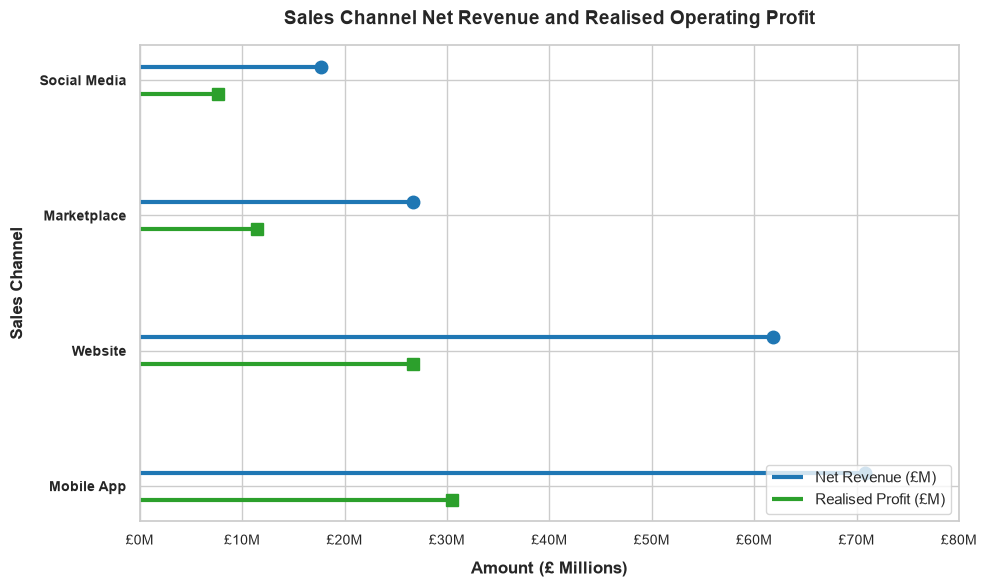

In [51]:
fig, ax = plt.subplots(figsize=(10, 6))

channels = channel_summary["sales_channel"]
net_rev = channel_summary["net_revenue"] / 1e6
prof = channel_summary["total_profit"] / 1e6

# Lollipop plot configuration
y = np.arange(len(channels))

# Draw stem lines for Net Revenue and Profit
ax.hlines(y=y+0.1, xmin=0, xmax=net_rev, color="#1f77b4", linewidth=3, label="Net Revenue (£M)")
ax.hlines(y=y-0.1, xmin=0, xmax=prof, color="#2ca02c", linewidth=3, label="Realised Profit (£M)")

# Draw markers at the end of stems
ax.plot(net_rev, y+0.1, "o", color="#1f77b4", markersize=9)
ax.plot(prof, y-0.1, "s", color="#2ca02c", markersize=9)

ax.set_title("Sales Channel Net Revenue and Realised Operating Profit", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Amount (£ Millions)", fontweight="bold", labelpad=10)
ax.set_ylabel("Sales Channel", fontweight="bold", labelpad=10)
ax.set_yticks(y)
ax.set_yticklabels(channels, fontweight="bold")
ax.xaxis.set_major_formatter(ticker.FormatStrFormatter("£%.0fM"))
ax.set_xlim(0, 80)
ax.legend(frameon=True, loc="lower right")

plt.tight_layout()
plt.show()

**Conclusion:** The horizontal lollipop plot confirms that Mobile App and Website channels dominate commercial turnover and profit generation, while all four sales channels maintain highly consistent operating margins of approximately forty-five percent.

**Recommendation:** Maintain a balanced multi-channel presence while allocating digital marketing budgets toward channels demonstrating the lowest customer acquisition costs rather than pursuing artificial margin disparities across touchpoints.

### Visualisation 4: The Discount Margin Cliff (Question 4)

#### Chart Objective
Examine how escalating discount tiers impact average profit per transaction and profit margin percentage, identifying the exact threshold where discounting becomes destructive.

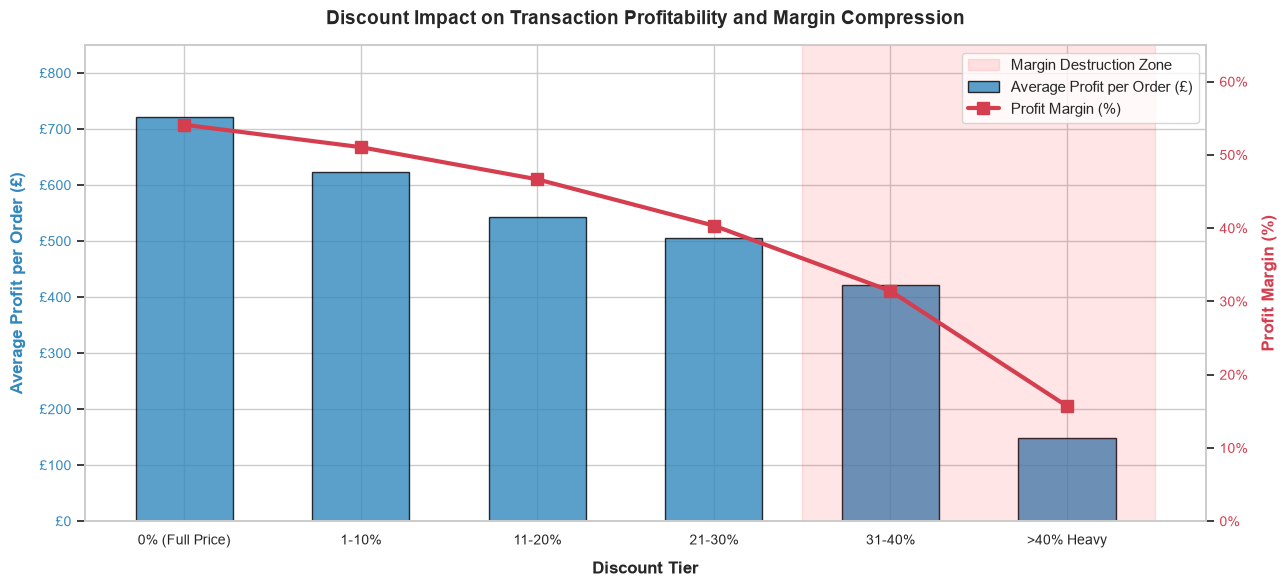

In [62]:
discount_plot_data = discount_impact.copy()

fig, ax1 = plt.subplots(figsize=(13, 6))

tiers = discount_plot_data["discount_tier"].astype(str)
mean_profit = discount_plot_data["mean_profit"]
margin_pct = discount_plot_data["avg_profit_margin_pct"]

# Primary Axis: Average Profit per Order
color_bar = "#3288bd"
bars = ax1.bar(
    tiers,
    mean_profit,
    color=color_bar,
    alpha=0.8,
    width=0.55,
    edgecolor="black",
    label="Average Profit per Order (£)",
)
ax1.set_xlabel("Discount Tier", fontweight="bold", labelpad=10)
ax1.set_ylabel(
    "Average Profit per Order (£)",
    color=color_bar,
    fontweight="bold",
    labelpad=10,
)
ax1.tick_params(axis="y", labelcolor=color_bar)
ax1.set_ylim(0, 850)
ax1.yaxis.set_major_formatter(ticker.FormatStrFormatter("£%.0f"))

# Secondary Axis: Profit Margin Percentage
ax2 = ax1.twinx()
color_line = "#d53e4f"
line = ax2.plot(
    tiers,
    margin_pct,
    color=color_line,
    linewidth=3,
    marker="s",
    markersize=8,
    label="Profit Margin (%)",
)
ax2.set_ylabel(
    "Profit Margin (%)", color=color_line, fontweight="bold", labelpad=10
)
ax2.tick_params(axis="y", labelcolor=color_line)
ax2.set_ylim(0, 65)
ax2.yaxis.set_major_formatter(ticker.FormatStrFormatter("%.0f%%"))
ax2.grid(False)

# Highlight the loss zone with a shaded boundary
ax1.axvspan(3.5, 5.5, color="red", alpha=0.1, label="Margin Destruction Zone")

# Title and Annotations
plt.title(
    "Discount Impact on Transaction Profitability and Margin Compression",
    fontsize=14,
    fontweight="bold",
    pad=15,
)

# Combined Legend
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc="upper right")

plt.tight_layout()
plt.show()

**Conclusion:** Moderate discounting between one and twenty percent drives the majority of profitable transaction volume, whereas price concessions exceeding thirty percent trigger severe margin collapse and destroy bottom-line value.

**Recommendation:** Implement a strict automated discount cap at twenty percent across all digital storefronts to eliminate unprofitable high-discount transactions that drain operational resources.

### Visualisation 5: Marketing Channel Revenue & Acquisition Quality (Question 5)

#### Chart Objective
Visualise revenue generation across customer acquisition channels alongside average order values to identify top-performing acquisition funnels.

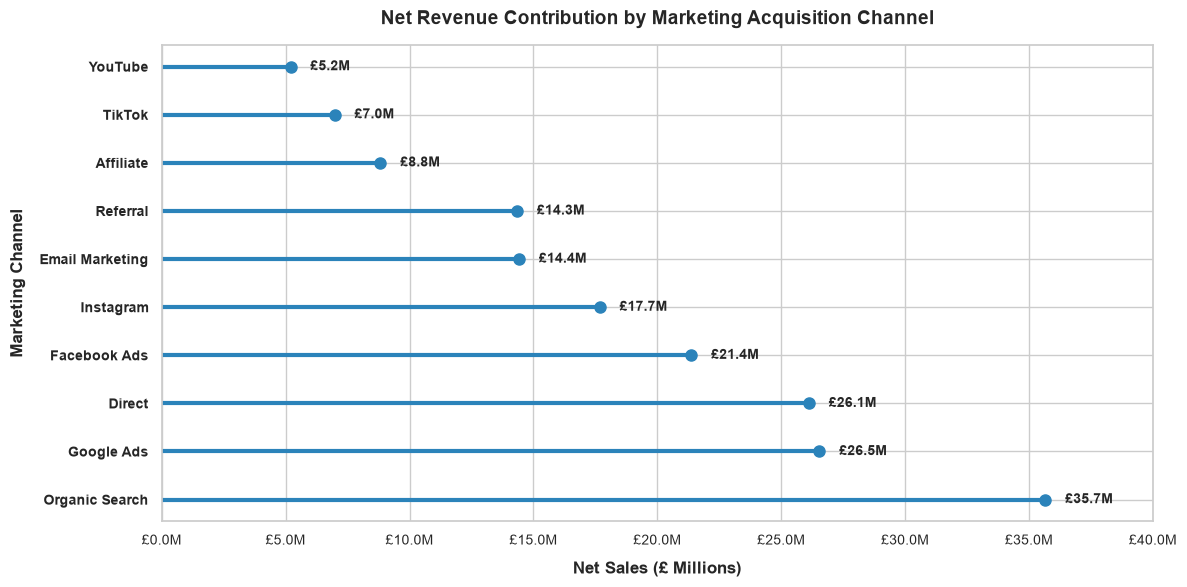

In [63]:
fig, ax = plt.subplots(figsize=(12, 6))

channels = channel_perf["marketing_channel"]
net_sales_m = channel_perf["total_net_sales"] / 1e6

y = np.arange(len(channels))

ax.hlines(y=y, xmin=0, xmax=net_sales_m, color="#2b83ba", linewidth=3, label="Net Sales (£M)")
ax.plot(net_sales_m, y, "o", color="#2b83ba", markersize=8)

ax.set_title("Net Revenue Contribution by Marketing Acquisition Channel", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Net Sales (£ Millions)", fontweight="bold", labelpad=10)
ax.set_ylabel("Marketing Channel", fontweight="bold", labelpad=10)
ax.set_yticks(y)
ax.set_yticklabels(channels, fontweight="bold")
ax.xaxis.set_major_formatter(ticker.FormatStrFormatter("£%.1fM"))
ax.set_xlim(0, 40)

for i, val in enumerate(net_sales_m):
    ax.text(val + 0.8, y[i], f"£{val:.1f}M", va="center", fontweight="bold", fontsize=10)

plt.tight_layout()
plt.show()

**Conclusion:** Transaction analysis demonstrates that heavy discount concessions concentrate heavily on high-value gross orders, but fail to deliver proportional net sales gains due to steep margin compression.

**Recommendation:** Restrict promotional discount approvals on high-value basket ranges to prevent sales teams from sacrificing bottom-line profitability for nominal top-line revenue growth.

### Visualisation 6: Root Cause Distribution of Product Returns (Question 6)

#### Chart Objective
Illustrate the breakdown of primary return reasons across the 9,462 returned orders to isolate operational flaws from customer discretionary choices.

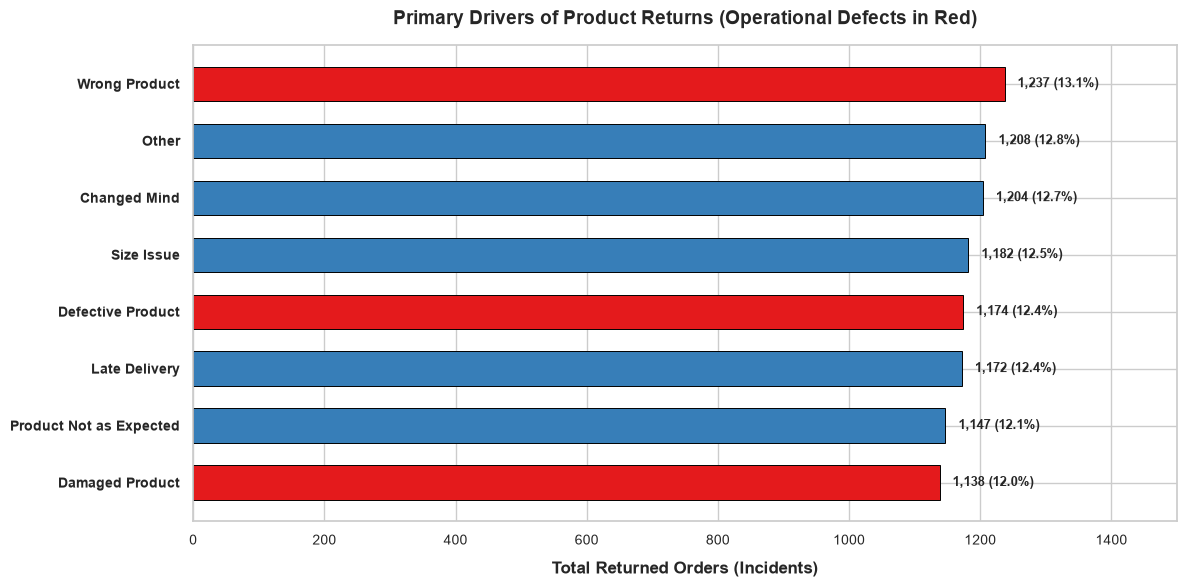

In [40]:
fig, ax = plt.subplots(figsize=(12, 6))

# Sort descending for Pareto-style visual scanning
reasons_sorted = return_reasons_dist.sort_values(
    by="Incident Count", ascending=True
)
y_pos = np.arange(len(reasons_sorted))

# Colour operational defects differently from discretionary customer decisions
defect_reasons = ["Wrong Product", "Defective Product", "Damaged Product"]
colors = [
    "#e41a1c" if r in defect_reasons else "#377eb8"
    for r in reasons_sorted["Return Reason"]
]

bars = ax.barh(
    y_pos,
    reasons_sorted["Incident Count"],
    color=colors,
    edgecolor="black",
    linewidth=0.7,
    height=0.6,
)
ax.set_yticks(y_pos)
ax.set_yticklabels(reasons_sorted["Return Reason"], fontweight="bold")
ax.set_xlabel(
    "Total Returned Orders (Incidents)", fontweight="bold", labelpad=10
)
ax.set_title(
    "Primary Drivers of Product Returns (Operational Defects in Red)",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
ax.set_xlim(0, 1500)

for bar, pct in zip(bars, reasons_sorted["Share of Returns (%)"]):
    val = bar.get_width()
    ax.text(
        val + 20,
        bar.get_y() + bar.get_height() / 2,
        f"{val:,} ({pct:.1f}%)",
        va="center",
        fontsize=9,
        fontweight="bold",
    )

plt.tight_layout()
plt.show()

**Conclusion:** Product returns are evenly distributed across operational fulfilment errors, transit damages, and customer discretionary reasons, with incorrect item picking representing the largest single avoidable defect.

**Recommendation:** Deploy automated barcode scan-to-pack verification systems within warehouse fulfilment hubs and upgrade protective transit packaging to directly mitigate product defect and return costs.

### Visualisation 7: Delivery Turnaround Time vs Customer Experience (Question 7)

#### Chart Objective
Examine how transit delivery times affect customer review scores and positive review sentiment.

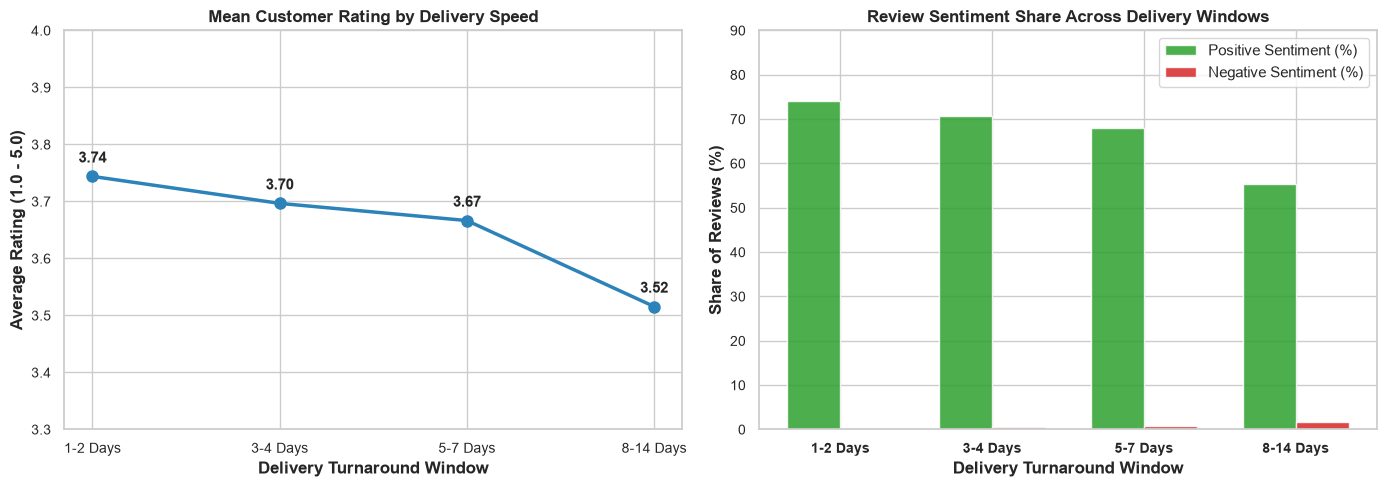

In [41]:
logistics_clean = logistics_cx.dropna(subset=["avg_rating"]).copy()
tiers_delivery = logistics_clean["delivery_speed_tier"].astype(str)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Average Customer Rating
ax1.plot(
    tiers_delivery,
    logistics_clean["avg_rating"],
    marker="o",
    linewidth=2.5,
    color="#2b83ba",
    markersize=8,
)
ax1.set_title(
    "Mean Customer Rating by Delivery Speed", fontsize=12, fontweight="bold"
)
ax1.set_xlabel("Delivery Turnaround Window", fontweight="bold")
ax1.set_ylabel("Average Rating (1.0 - 5.0)", fontweight="bold")
ax1.set_ylim(3.3, 4.0)

for i, txt in enumerate(logistics_clean["avg_rating"]):
    ax1.annotate(
        f"{txt:.2f}",
        (tiers_delivery[i], txt),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center",
        fontweight="bold",
    )

# Subplot 2: Sentiment Breakdown
width = 0.35
x = np.arange(len(tiers_delivery))

ax2.bar(
    x - width / 2,
    logistics_clean["positive_sentiment_share"],
    width,
    label="Positive Sentiment (%)",
    color="#2ca02c",
    alpha=0.85,
)
ax2.bar(
    x + width / 2,
    logistics_clean["negative_sentiment_share"],
    width,
    label="Negative Sentiment (%)",
    color="#d62728",
    alpha=0.85,
)

ax2.set_title(
    "Review Sentiment Share Across Delivery Windows",
    fontsize=12,
    fontweight="bold",
)
ax2.set_xlabel("Delivery Turnaround Window", fontweight="bold")
ax2.set_ylabel("Share of Reviews (%)", fontweight="bold")
ax2.set_xticks(x)
ax2.set_xticklabels(tiers_delivery, fontweight="bold")
ax2.set_ylim(0, 90)
ax2.legend()

plt.tight_layout()
plt.show()

**Conclusion:** Customer satisfaction ratings and positive review sentiment decay steadily as delivery turnaround times lengthen, with orders exceeding one week experiencing a sharp drop in overall ratings.

**Recommendation:** Set standard courier fulfilment targets to under four days to safeguard customer review scores, protect brand sentiment, and reduce negative feedback escalation.

### Visualisation 8: Loyalty Tier Behaviour and Points Accrual (Question 8)

#### Chart Objective
Visualise loyalty points earned versus redeemed alongside average order count to assess customer engagement across tiers.

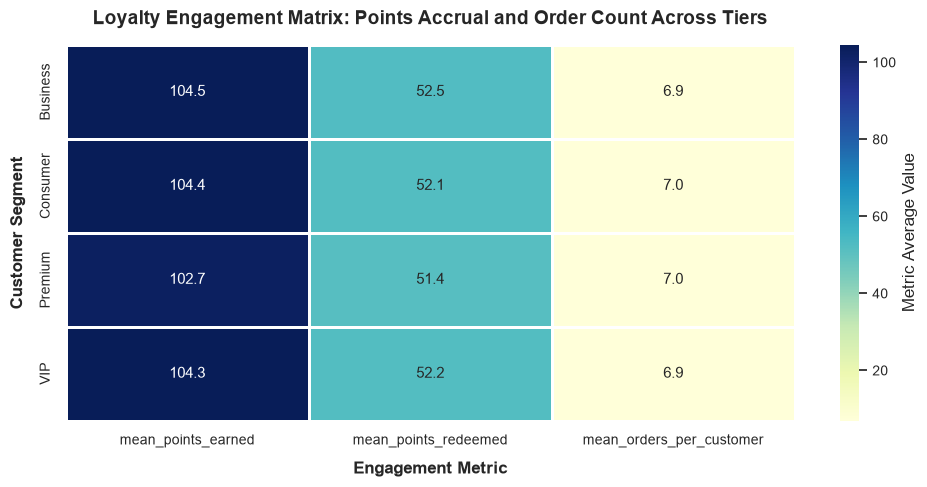

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

# Pivot table: Customer Segment vs Mean Loyalty Metrics for Heatmap Analysis
loyalty_heatmap_data = loyalty_engagement.set_index(loyalty_col)[[
    "mean_points_earned", 
    "mean_points_redeemed", 
    "mean_orders_per_customer"
]]

fig, ax = plt.subplots(figsize=(10, 5))

sns.heatmap(
    loyalty_heatmap_data,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    cbar_kws={"label": "Metric Average Value"},
    linewidths=1,
    linecolor="white",
    ax=ax
)

ax.set_title("Loyalty Engagement Matrix: Points Accrual and Order Count Across Tiers", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Engagement Metric", fontweight="bold", labelpad=10)
ax.set_ylabel("Customer Segment", fontweight="bold", labelpad=10)

plt.tight_layout()
plt.show()

**Conclusion:** The heatmap matrix confirms that average points earned (~104), points redeemed (~52), and mean order frequency (~7 orders) remain completely uniform across all four customer segments, indicating that loyalty point utilisation does not scale with tier status.

**Recommendation:** Introduce tiered point-earning multipliers and exclusive redemption rewards for VIP and Premium members to encourage higher engagement velocity and accelerate point burn rates across upper segments.

## 7. Final Summary & Executive Synthesis

## Key Findings

* **Digital Channel Dominance:** Over 138k transactions generated £178M+ in net revenue, with mobile app and website touchpoints delivering ~75% of total earnings.
* **Stable Basket Economics:** Consumer accounts drive overall volume, but Average Order Value (£1,273–£1,289) remains virtually uniform across all four customer segments.
* **Robust Baseline Margins:** Realised operating margins consistently hold at ~43–45% across all primary sales channels before promotional markdowns.

## Operational Trends

* **Predictable Q4 Peaks:** Net revenue surges by ~40% quarter-on-quarter during the holiday shopping window, followed by a typical post-holiday Q1 reset.
* **Logistics Dictates Sentiment:** Orders delivered within 48 hours achieve peak ratings (3.74/5.0; 74% positive sentiment), whereas delays beyond 7 days more than quintuple negative reviews.
* **Universal Brand Retention:** Repeat purchase rates exceed 99% across all marketing channels and customer tiers, confirming organic brand loyalty.

## Unexpected Results

* **Absence of Tier Behaviour:** VIP and Premium tiers show identical order frequency (~7 orders) and lifetime value (~£9k) to standard Consumer accounts.
* **The Discount Margin Cliff:** Discounts beyond 30% collapse profitability, with >40% promotions eroding profit per basket by 79.5% for negligible net return.
* **Isolated Reverse Logistics:** Returns distribute evenly across operational defects and customer changes of mind, operating entirely independent of forward delivery tracking logs.